# 5주차 워크북 4 · 시장 지수(KOSPI·KOSDAQ)와 개별 종목 수익률 비교 — 완성본

개별 종목의 움직임이 **시장 전체와 얼마나 같이 움직였는지**를 수익률·변동성·상관계수·베타로 비교하고,
그 통계표를 AI에게 요약시켜 근거를 검증합니다.

- 데이터: 한국거래소(KRX) 종목 일별 시세 + KOSPI·KOSDAQ 지수 일별 (2025-01-02 ~ 2026-10-13). **API 키 불필요.**
- 공식 API로 직접 수집하려면 `Week05_데이터수집_API가이드.ipynb`의 방법 C(금융위원회 주식·지수시세) 사용.


> 교육용 분석이며 매매 추천이 아닙니다.

In [1]:
!pip -q install koreanize-matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re
import koreanize_matplotlib

BASE = "https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week05/data/"
STOCKS = {"005930": "삼성전자", "000660": "SK하이닉스", "005380": "현대차"}

## 1. 불러오기 · 공통 정제 함수

In [2]:
def clean_series(df, date_col, close_col, name):
    # 날짜·종가만 남기고 형 변환 → 결측·중복 제거 → 날짜 오름차순 → 일간 수익률(%)
    x = df[[date_col, close_col]].copy()
    x.columns = ["Date", "Close"]
    x["Date"] = pd.to_datetime(x["Date"], errors="coerce")
    x["Close"] = pd.to_numeric(x["Close"], errors="coerce")
    x = x.dropna().drop_duplicates("Date").sort_values("Date").set_index("Date")
    return x["Close"].rename(name)

closes = {name: clean_series(pd.read_csv(BASE + f"krx_daily_{code}.csv"), "Date", "Close", name)
          for code, name in STOCKS.items()}
closes["KOSPI"] = clean_series(pd.read_csv(BASE + "kospi_daily.csv"), "Date", "Close", "KOSPI")
closes["KOSDAQ"] = clean_series(pd.read_csv(BASE + "kosdaq_daily.csv"), "Date", "Close", "KOSDAQ")
pd.DataFrame({k: [len(v), v.index.min().date(), v.index.max().date()] for k, v in closes.items()},
             index=["행 수", "시작일", "종료일"])

,삼성전자,SK하이닉스,현대차,KOSPI,KOSDAQ
행 수,431,431,431,431,431
시작일,2025-01-02,2025-01-02,2025-01-02,2025-01-02,2025-01-02
종료일,2026-10-13,2026-10-13,2026-10-13,2026-10-13,2026-10-13


## 2. 공통 거래일로 합치기

In [3]:
price = pd.concat(closes.values(), axis=1, join="inner")      # 모든 시계열에 있는 날짜만
ret = price.pct_change().mul(100).dropna()                     # 일간 수익률(%)
print("공통 거래일:", len(price), "일 → 수익률 계산 가능:", len(ret), "일")
ret.tail()

공통 거래일: 431 일 → 수익률 계산 가능: 430 일


,삼성전자,SK하이닉스,현대차,KOSPI,KOSDAQ
Date,,,,,
2026-10-06,-1.449275,-3.693645,0.432900,-0.890239,2.981115
2026-10-07,-1.286765,-2.820079,-3.448276,-1.980727,-2.336073
2026-10-08,-2.420857,-2.437609,-3.422619,-2.615706,-0.685641
2026-10-12,-4.389313,-4.521118,-1.386749,-3.647639,-4.828135
2026-10-13,-7.385230,-10.093458,-1.562500,-5.464863,-1.431953


✔ **기대값:** 공통 거래일 431일 → 수익률 430일

## 3. 비교표 (Notion 워크북 4 표 채우기)

In [4]:
cum = (price.iloc[-1] / price.iloc[0] - 1) * 100
beta = ret.cov()["KOSPI"] / ret["KOSPI"].var()               # 시장(KOSPI) 대비 민감도
comp = pd.DataFrame({
    "조회 기준기간": f"{price.index[0].date()} ~ {price.index[-1].date()}",
    "총 거래일 수": len(price),
    "평균 일수익률%": ret.mean().round(3),
    "일수익률 표준편차%": ret.std().round(2),
    "연율화 변동성%": (ret.std() * np.sqrt(252)).round(1),
    "기간 누적수익률%": cum.round(1),
    "상승일 비율%": (ret.gt(0).mean() * 100).round(1),
    "KOSPI와 상관계수": ret.corr()["KOSPI"].round(2),
    "KOSPI 대비 베타": beta.round(2),
    "자료 출처": ["KRX 종목 시세"] * 3 + ["KRX 지수(KS11)", "KRX 지수(KQ11)"],
}).T
comp

,삼성전자,SK하이닉스,현대차,KOSPI,KOSDAQ
조회 기준기간,2025-01-02 ~ 2026-10-13,2025-01-02 ~ 2026-10-13,2025-01-02 ~ 2026-10-13,2025-01-02 ~ 2026-10-13,2025-01-02 ~ 2026-10-13
총 거래일 수,431,431,431,431,431
평균 일수익률%,0.415,0.613,0.154,0.252,0.076
일수익률 표준편차%,3.86,4.85,3.52,2.73,2.46
연율화 변동성%,61.3,77.0,55.8,43.3,39.1
기간 누적수익률%,334.5,742.9,48.9,151.6,21.9
상승일 비율%,53.7,54.9,48.4,61.6,56.3
KOSPI와 상관계수,0.91,0.89,0.62,1.0,0.74
KOSPI 대비 베타,1.29,1.58,0.8,1.0,0.67
자료 출처,KRX 종목 시세,KRX 종목 시세,KRX 종목 시세,KRX 지수(KS11),KRX 지수(KQ11)


**읽는 법**
- **상관계수**: 1에 가까울수록 KOSPI와 같은 방향으로 움직인 날이 많았다.
- **베타**: KOSPI가 1% 움직일 때 평균적으로 몇 % 움직였나(과거 관측). 삼성전자·SK하이닉스는 KOSPI 시가총액에서 비중이 커서 지수 자체에 영향을 준다는 점도 함께 생각한다.
- 평균 일수익률은 작아 보여도 430일 누적되면 큰 차이가 된다.

## 4. 시각화

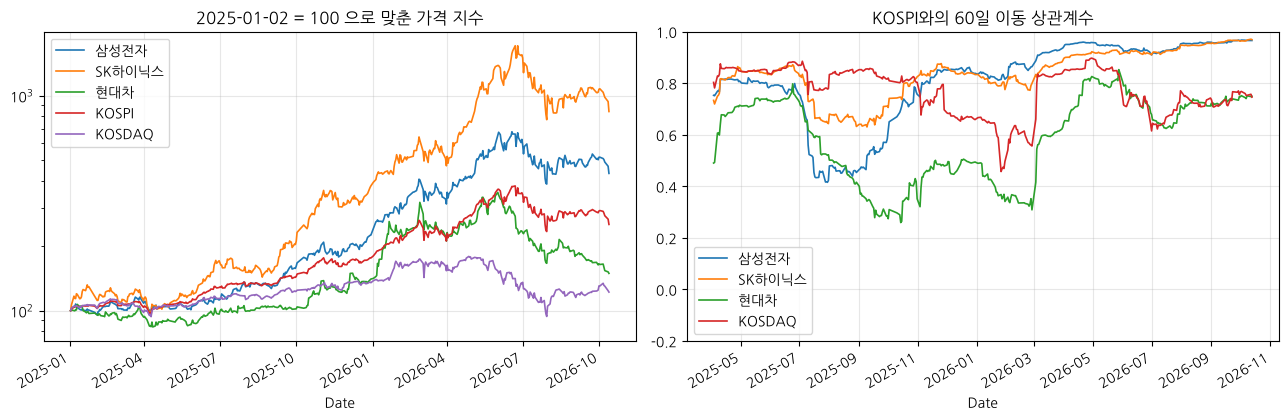

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
(price / price.iloc[0] * 100).plot(ax=ax1, lw=1.2)
ax1.set_title("2025-01-02 = 100 으로 맞춘 가격 지수"); ax1.set_yscale("log"); ax1.grid(alpha=0.3)
roll = ret.rolling(60).corr(ret["KOSPI"]).drop(columns="KOSPI")
roll.plot(ax=ax2, lw=1.2)
ax2.set_title("KOSPI와의 60일 이동 상관계수"); ax2.set_ylim(-0.2, 1); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_week05_wb4_index_compare.png", dpi=120); plt.show()

In [6]:
ret.corr().round(2).style.background_gradient(cmap="Blues", vmin=0, vmax=1)

,삼성전자,SK하이닉스,현대차,KOSPI,KOSDAQ
삼성전자,1.000000,0.800000,0.530000,0.910000,0.590000
SK하이닉스,0.800000,1.000000,0.460000,0.890000,0.590000
현대차,0.530000,0.460000,1.000000,0.620000,0.480000
KOSPI,0.910000,0.890000,0.620000,1.000000,0.740000
KOSDAQ,0.590000,0.590000,0.480000,0.740000,1.000000


## 5. AI 비교 프롬프트와 숫자 검증

In [7]:
stat_cols = ["평균 일수익률%", "일수익률 표준편차%", "기간 누적수익률%", "KOSPI와 상관계수", "KOSPI 대비 베타"]
stat_tbl = comp.loc[stat_cols].T.reset_index().rename(columns={"index": "시계열"})
prompt = f"""아래 기술 통계표에 있는 사실만으로 세 종목과 두 지수의 수익률·변동성·시장 연동성을 비교하세요.
모든 주장 끝에 근거 열 이름을 [열이름]으로 붙이세요. 미래 전망·인과관계·매매 추천은 하지 마세요.
표에 없는 원인은 '확인 불가'라고 쓰세요. 기간: {comp.loc['조회 기준기간'].iloc[0]}

{stat_tbl.to_markdown(index=False)}
"""
print(prompt)

아래 기술 통계표에 있는 사실만으로 세 종목과 두 지수의 수익률·변동성·시장 연동성을 비교하세요.
모든 주장 끝에 근거 열 이름을 [열이름]으로 붙이세요. 미래 전망·인과관계·매매 추천은 하지 마세요.
표에 없는 원인은 '확인 불가'라고 쓰세요. 기간: 2025-01-02 ~ 2026-10-13

| 시계열     |   평균 일수익률% |   일수익률 표준편차% |   기간 누적수익률% |   KOSPI와 상관계수 |   KOSPI 대비 베타 |
|:-----------|-----------------:|---------------------:|-------------------:|-------------------:|------------------:|
| 삼성전자   |            0.415 |                 3.86 |              334.5 |               0.91 |              1.29 |
| SK하이닉스 |            0.613 |                 4.85 |              742.9 |               0.89 |              1.58 |
| 현대차     |            0.154 |                 3.52 |               48.9 |               0.62 |              0.8  |
| KOSPI      |            0.252 |                 2.73 |              151.6 |               1    |              1    |
| KOSDAQ     |            0.076 |                 2.46 |               21.9 |               0.74 |              0.67 |



In [8]:
ai_text = """
여기에 AI 응답을 붙여 넣으세요
"""

def check_numbers(text, table, tol=0.01):
    vals = pd.to_numeric(table.select_dtypes("number").stack(), errors="coerce").dropna().values
    out = []
    for tok in re.findall(r"(?<![A-Za-z\d.])-?(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?", text):
        v = float(tok.replace(",", ""))
        ok = np.any(np.isclose(vals, v, rtol=tol, atol=0.006))
        out.append({"AI가 쓴 숫자": tok, "판정": "표에 있음 ✔" if ok else "표에 없음 ✘ → 직접 확인"})
    return pd.DataFrame(out).drop_duplicates()

tbl_num = stat_tbl.copy()
for c in stat_cols:
    tbl_num[c] = pd.to_numeric(tbl_num[c])
check_numbers(ai_text, tbl_num)

""


## 제출 체크리스트
- [ ] 비교표(3절)와 그림 저장, 자료 출처·기간 기재
- [ ] AI 프롬프트·응답 원문·서비스명/시각
- [ ] 숫자 검증 결과 + 표 밖 정보·인과·추천 표현 판정
- [ ] "베타가 높다 = 앞으로도 더 오른다"가 왜 틀린 해석인지 한 문단
- [ ] (심화) 공공데이터포털 지수시세 API로 KOSPI를 직접 받아 이 표의 KOSPI 종가와 대조